# Phishing Website Detection Using Machine Learning

**Foundations of Data Science (INT3142), Assignment 3**

This notebook loads the original UCI Phishing Websites dataset, audits and cleans records, performs EDA and statistical tests, and evaluates a baseline and three classifiers on a stratified held-out test set. Positive class `1` means phishing. Source: [UCI dataset 327](https://archive.ics.uci.edu/dataset/327/phishing+websites).

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd()
if not (ROOT / 'src').exists(): ROOT = Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
from src.utils import ensure_directories
from src.data_loader import load_raw_dataset
from src.data_cleaning import clean_dataset
from src.eda import run_eda
from src.statistical_analysis import run_statistical_tests
from src.model_training import train_models
from src.model_evaluation import evaluate_models, save_importance
ensure_directories()
print('Project root:', ROOT)

Project root: C:\IT\A\FDS\phishing-detection-fds


## 2. Dataset acquisition

In [2]:
raw = load_raw_dataset()
print('Source: UCI Phishing Websites, dataset 327')
print('Raw shape:', raw.shape)
raw.head()

Source: UCI Phishing Websites, dataset 327
Raw shape: (11055, 31)


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


## 3. Inspect source schema and labels

In [3]:
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum()}))
print('Duplicate rows:', int(raw.duplicated().sum()))
print('Result labels:', raw['Result'].value_counts(dropna=False).to_dict())
print('Number of unique codes per feature:')
display(raw.drop(columns='Result').nunique().value_counts().rename_axis('unique_codes_per_feature').to_frame('feature_count'))

,dtype,missing
having_IP_Address,int64,0
URL_Length,int64,0
Shortining_Service,int64,0
having_At_Symbol,int64,0
double_slash_redirecting,int64,0
Prefix_Suffix,int64,0
having_Sub_Domain,int64,0
SSLfinal_State,int64,0
Domain_registeration_length,int64,0
Favicon,int64,0


Duplicate rows: 5206
Result labels: {1: 6157, -1: 4898}
Number of unique codes per feature:


,feature_count
unique_codes_per_feature,
2,22
3,8


## 4. Data cleaning

In [4]:
cleaned, missing = clean_dataset(raw)
print('Cleaned shape:', cleaned.shape)
display(cleaned['is_phishing'].value_counts().rename(index={0:'Legitimate',1:'Phishing'}).to_frame('records'))
display(pd.read_csv('outputs/summaries/cleaning_summary.csv'))
print('IQR outlier flags are saved; discrete indicator values are retained.')

Cleaned shape: (5849, 31)


,records
is_phishing,
Phishing,3019
Legitimate,2830


,item,value
0,rows_before,11055
1,columns_before,31
2,duplicate_rows_removed,5206
3,invalid_or_missing_rows_removed,0
4,rows_after,5849
5,columns_after_including_target,31
6,missing_cells_before,0
7,outlier_policy,IQR flags reported; no discrete feature rows r...
8,target_mapping,Result=-1 phishing => is_phishing=1; Result=1 ...
9,class_counts,"{0: 2830, 1: 3019}"


IQR outlier flags are saved; discrete indicator values are retained.


## 5. Descriptive statistics

In [5]:
display(cleaned.drop(columns='is_phishing').describe().T.head(12))
print('Full descriptive statistics: outputs/summaries/descriptive_statistics.csv')

,count,mean,std,min,25%,50%,75%,max
having_IP_Address,5849.0,0.132843,0.991222,-1.0,-1.0,1.0,1.0,1.0
URL_Length,5849.0,-0.616003,0.777323,-1.0,-1.0,-1.0,-1.0,1.0
Shortining_Service,5849.0,0.720294,0.693728,-1.0,1.0,1.0,1.0,1.0
having_At_Symbol,5849.0,0.588648,0.808459,-1.0,1.0,1.0,1.0,1.0
double_slash_redirecting,5849.0,0.718242,0.695852,-1.0,1.0,1.0,1.0,1.0
Prefix_Suffix,5849.0,-0.760301,0.649627,-1.0,-1.0,-1.0,-1.0,1.0
having_Sub_Domain,5849.0,0.065823,0.802448,-1.0,-1.0,0.0,1.0,1.0
SSLfinal_State,5849.0,0.149085,0.924473,-1.0,-1.0,1.0,1.0,1.0
Domain_registeration_length,5849.0,-0.305864,0.952157,-1.0,-1.0,-1.0,1.0,1.0
Favicon,5849.0,0.581809,0.813395,-1.0,1.0,1.0,1.0,1.0


Full descriptive statistics: outputs/summaries/descriptive_statistics.csv


## 6. EDA visualizations

class_distribution.png


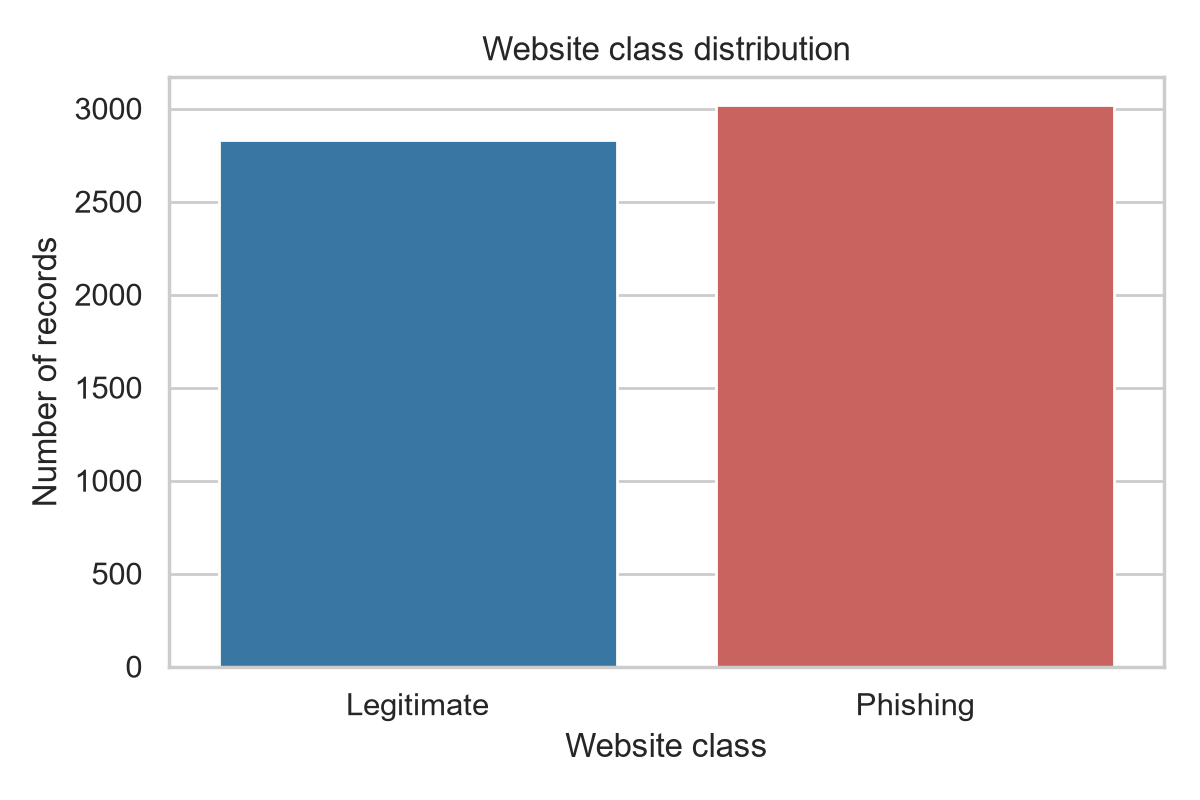

missing_values.png


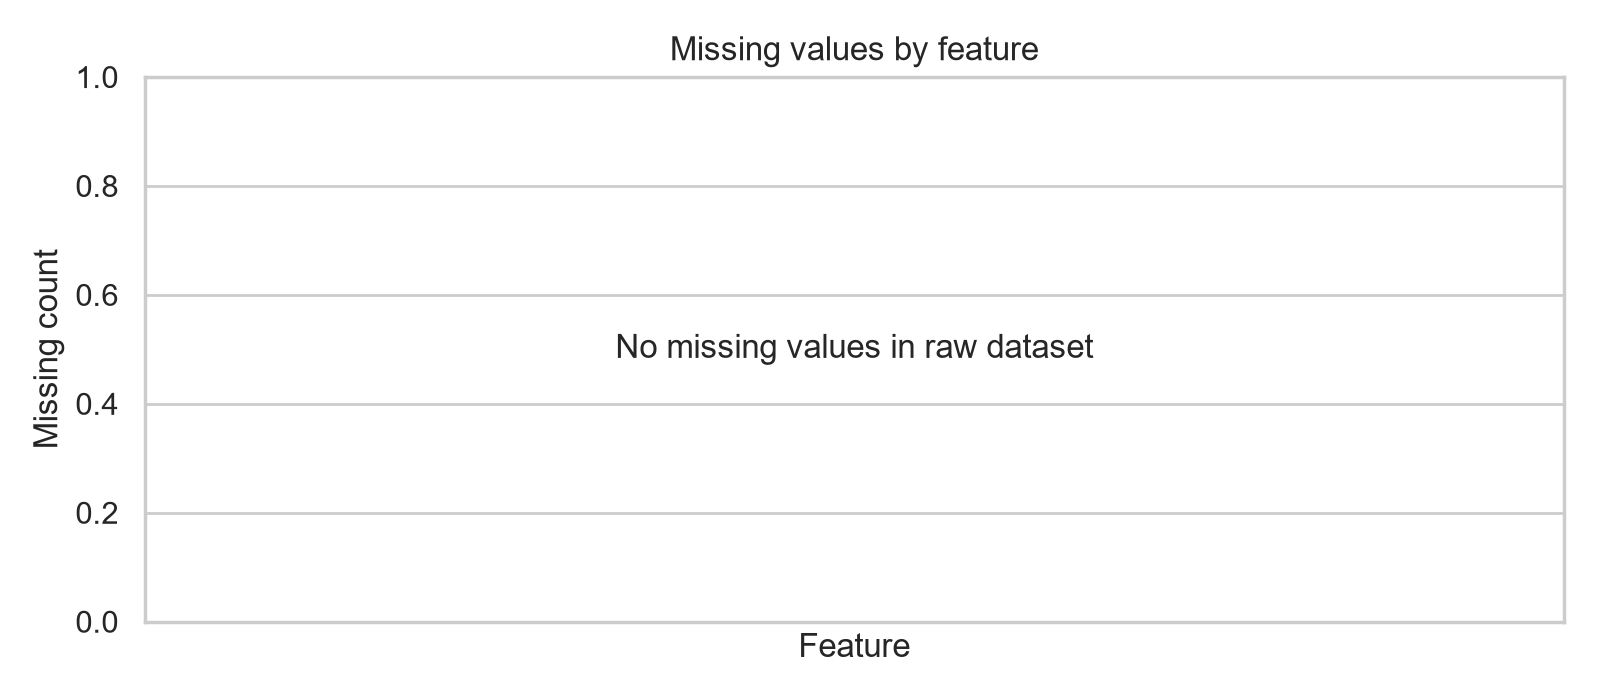

correlation_heatmap.png


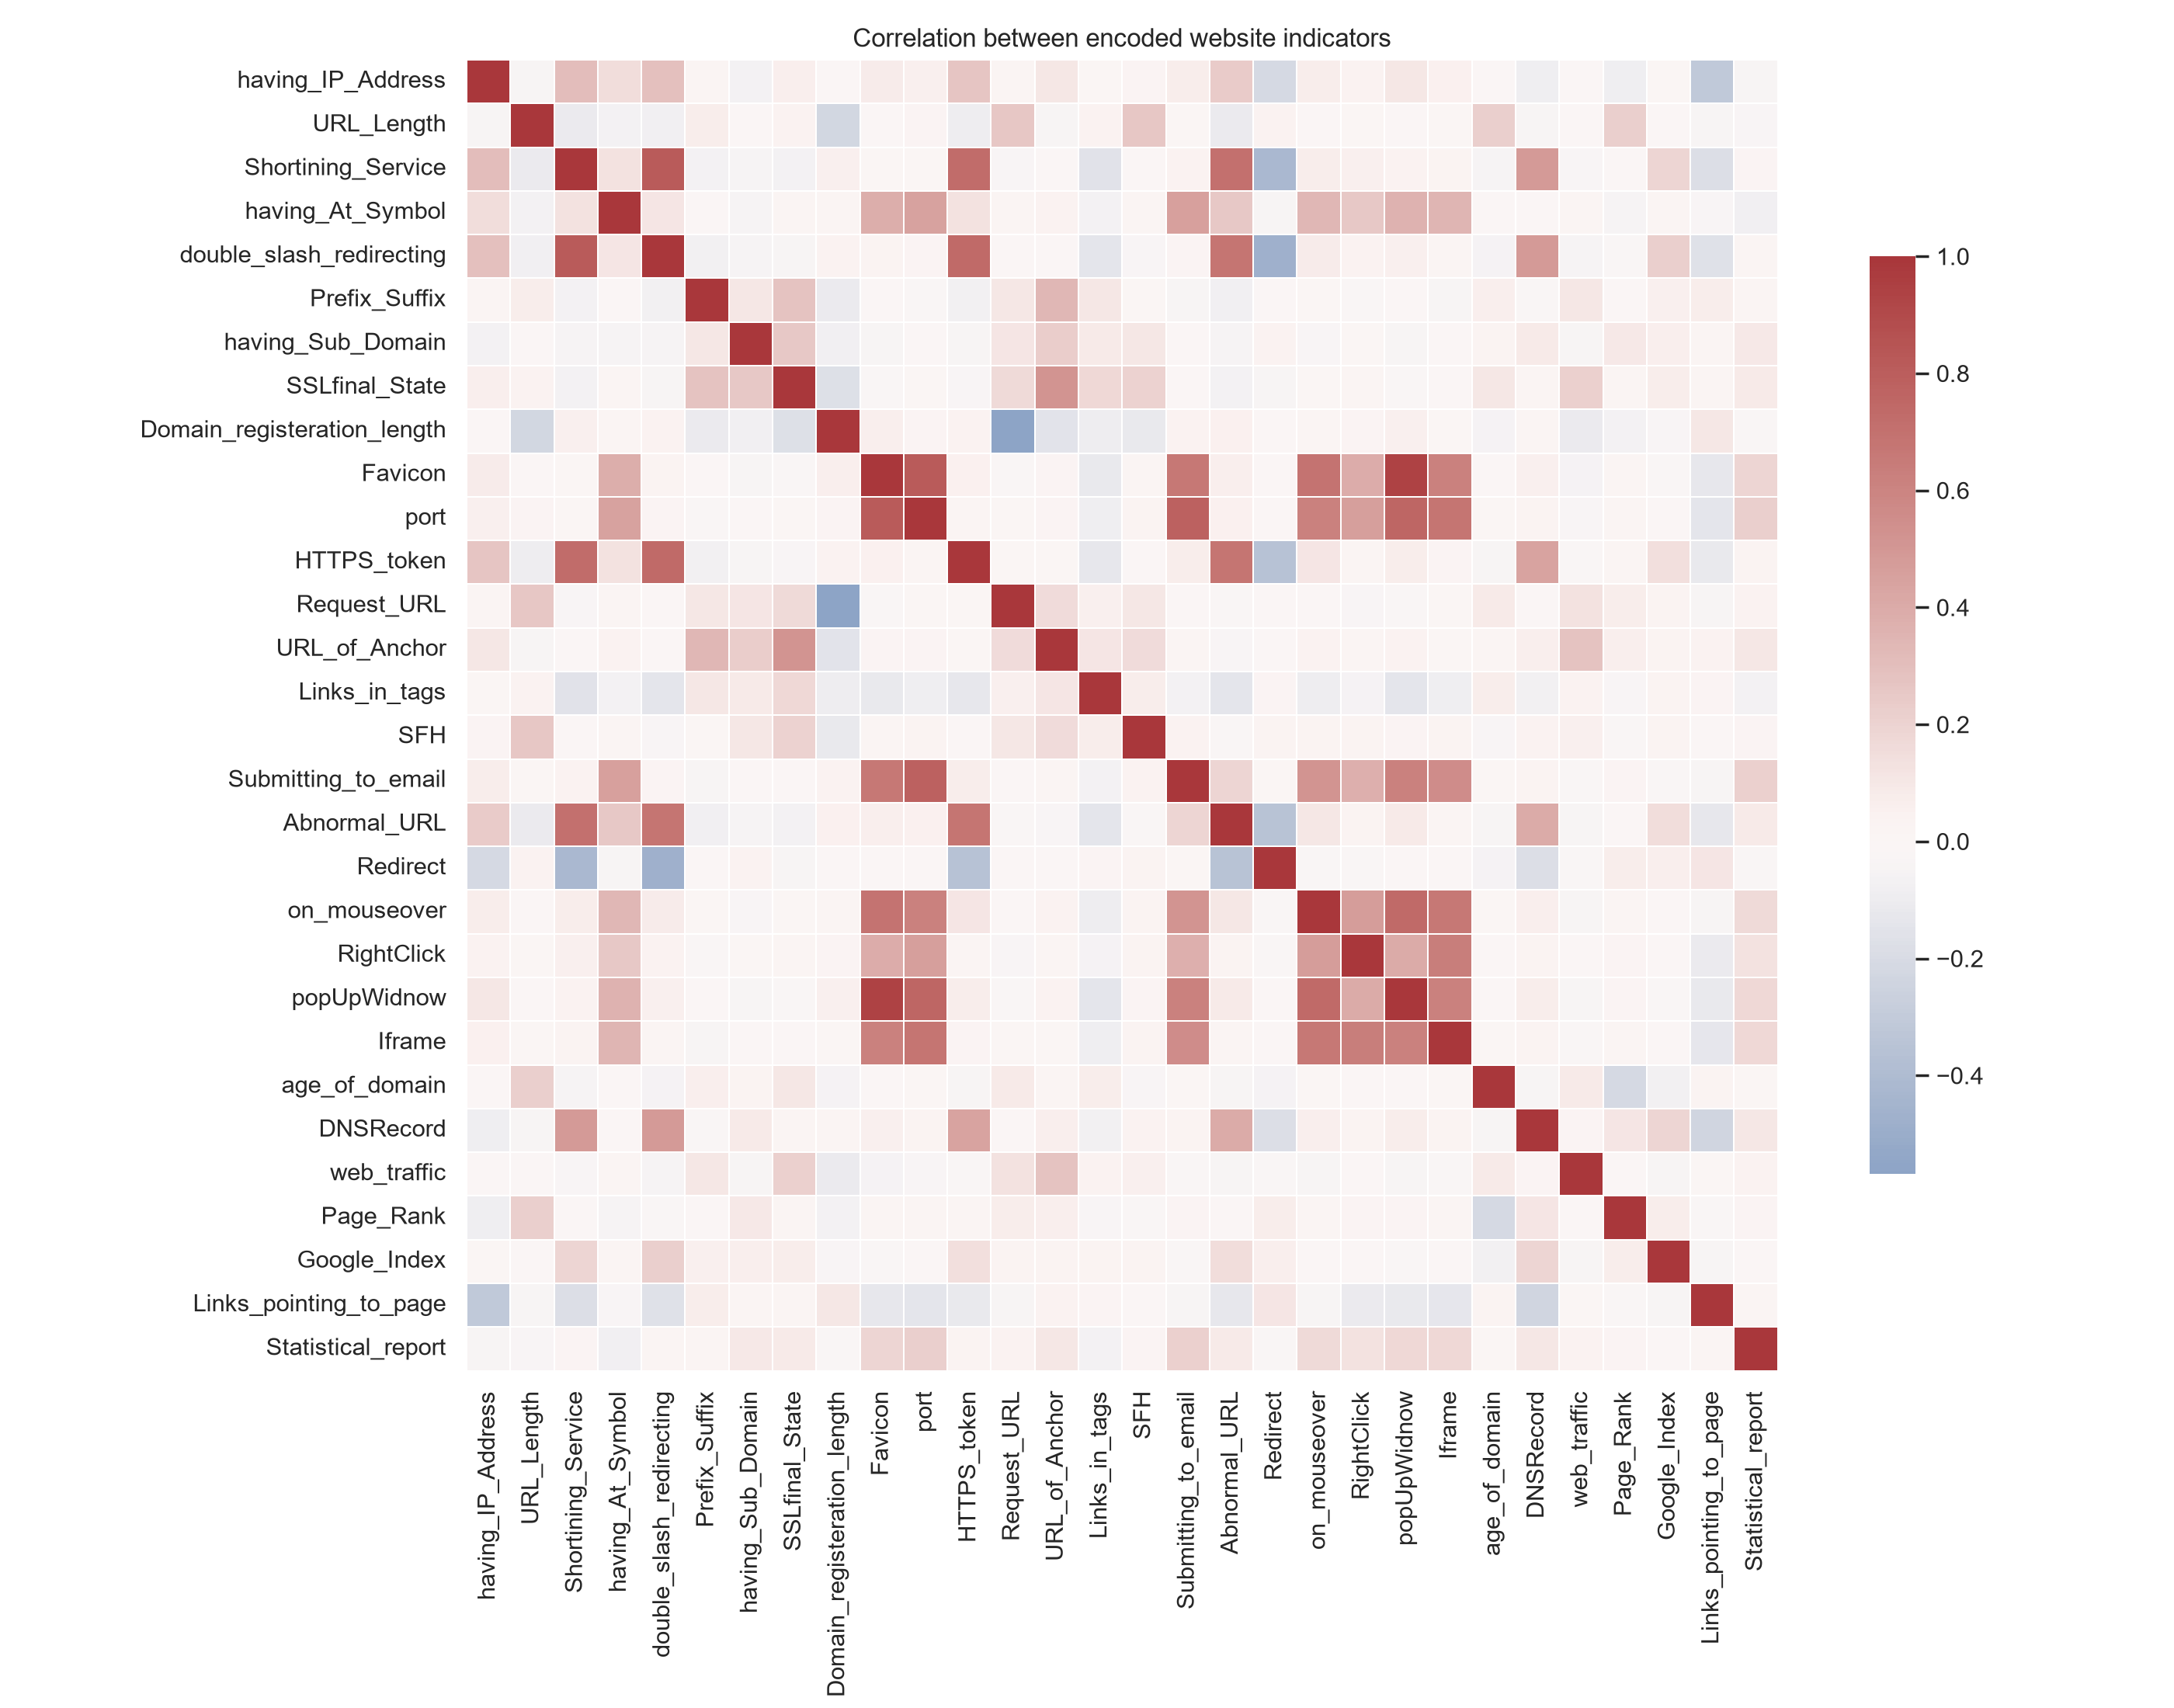

feature_distribution.png


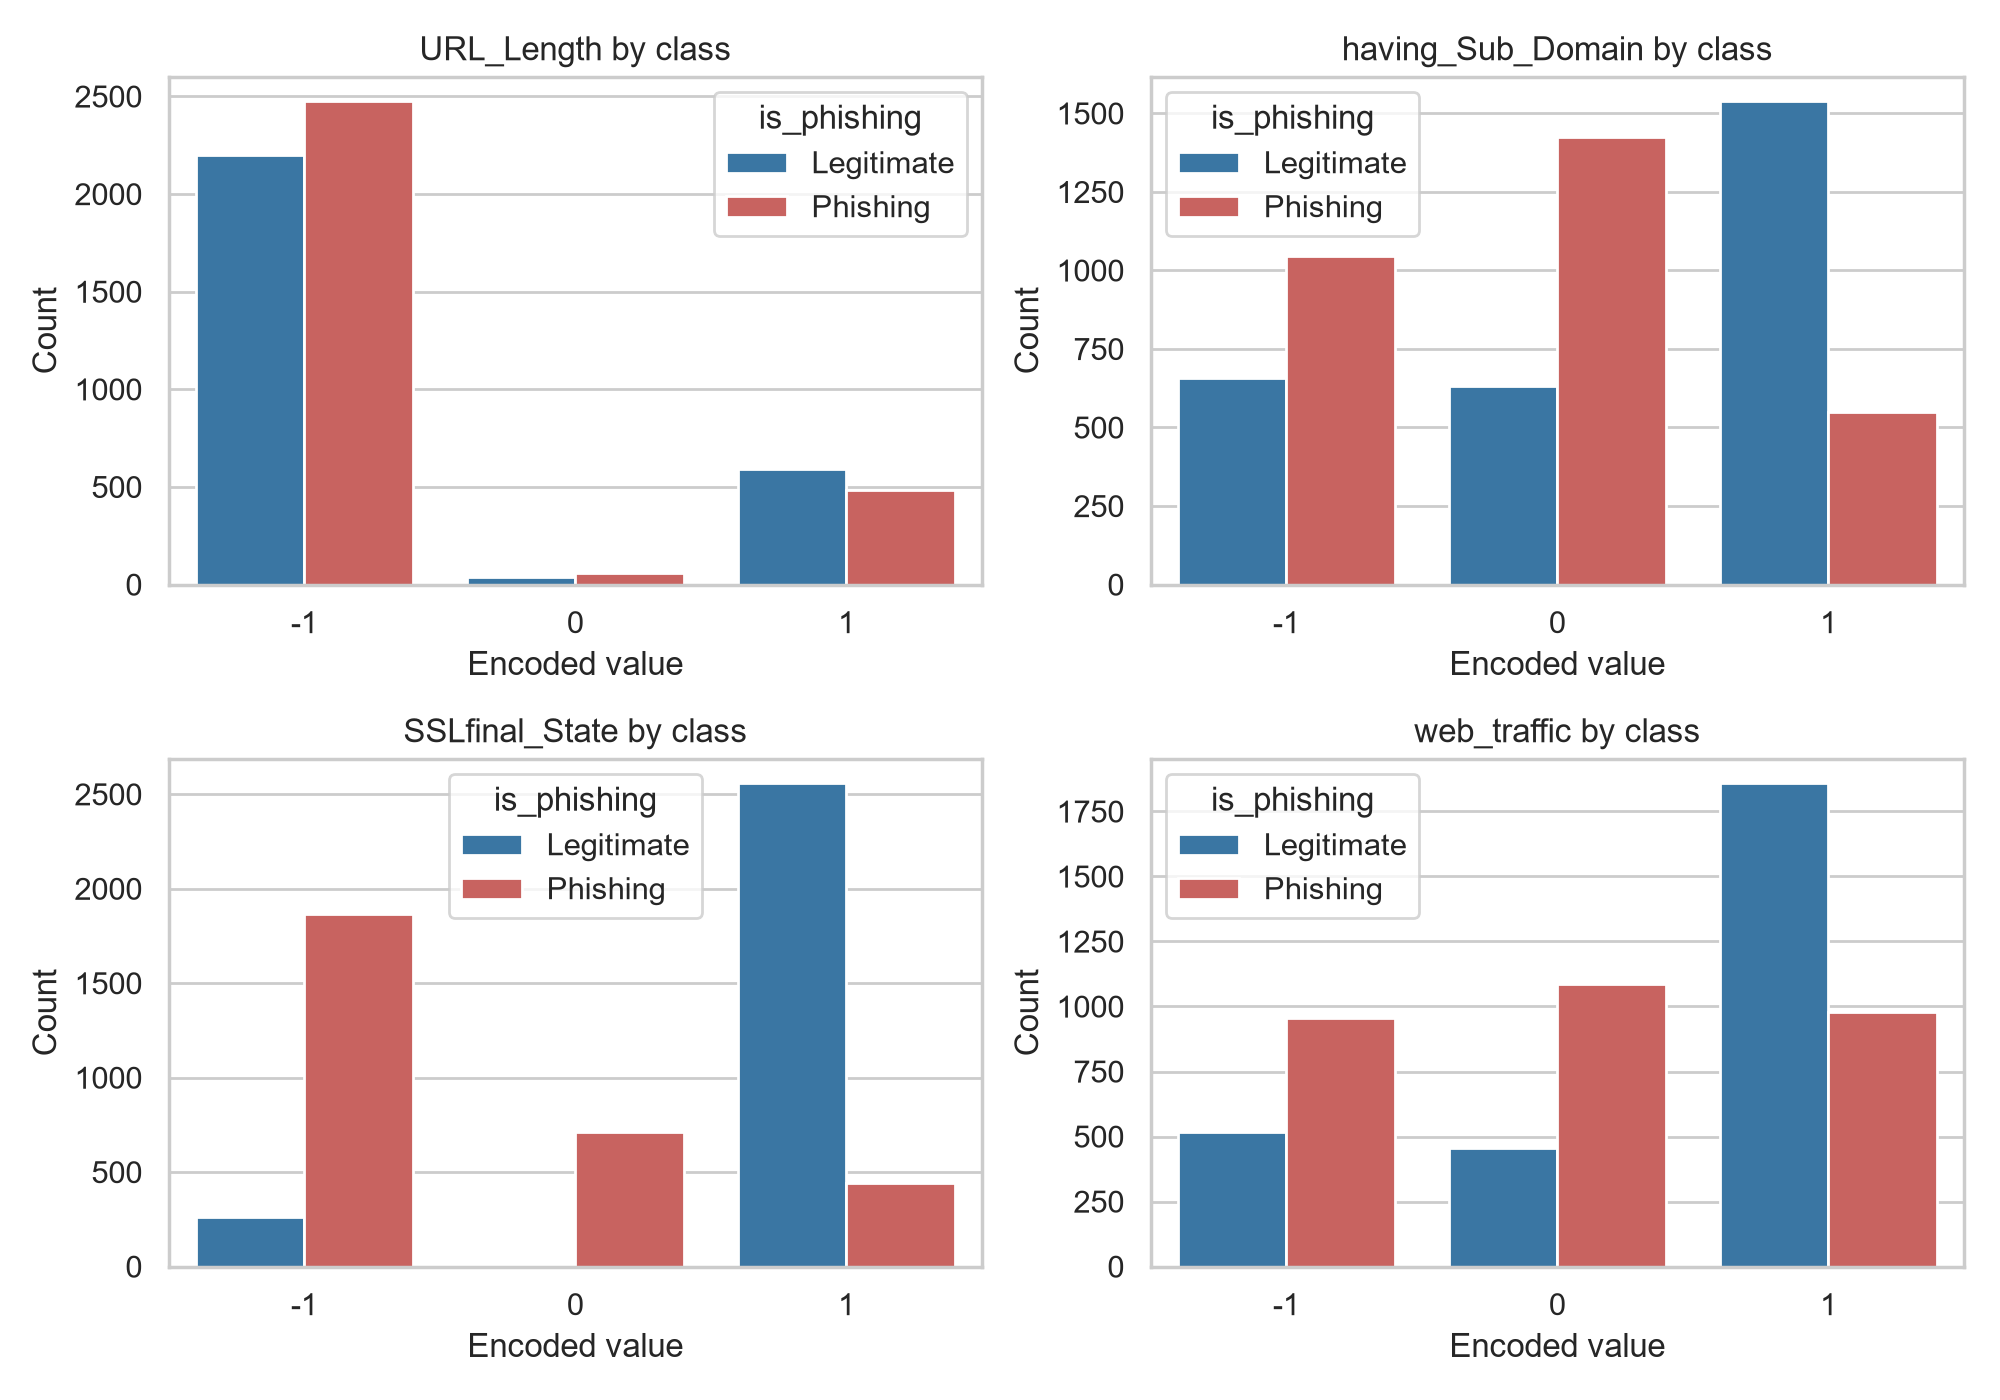

feature_boxplots.png


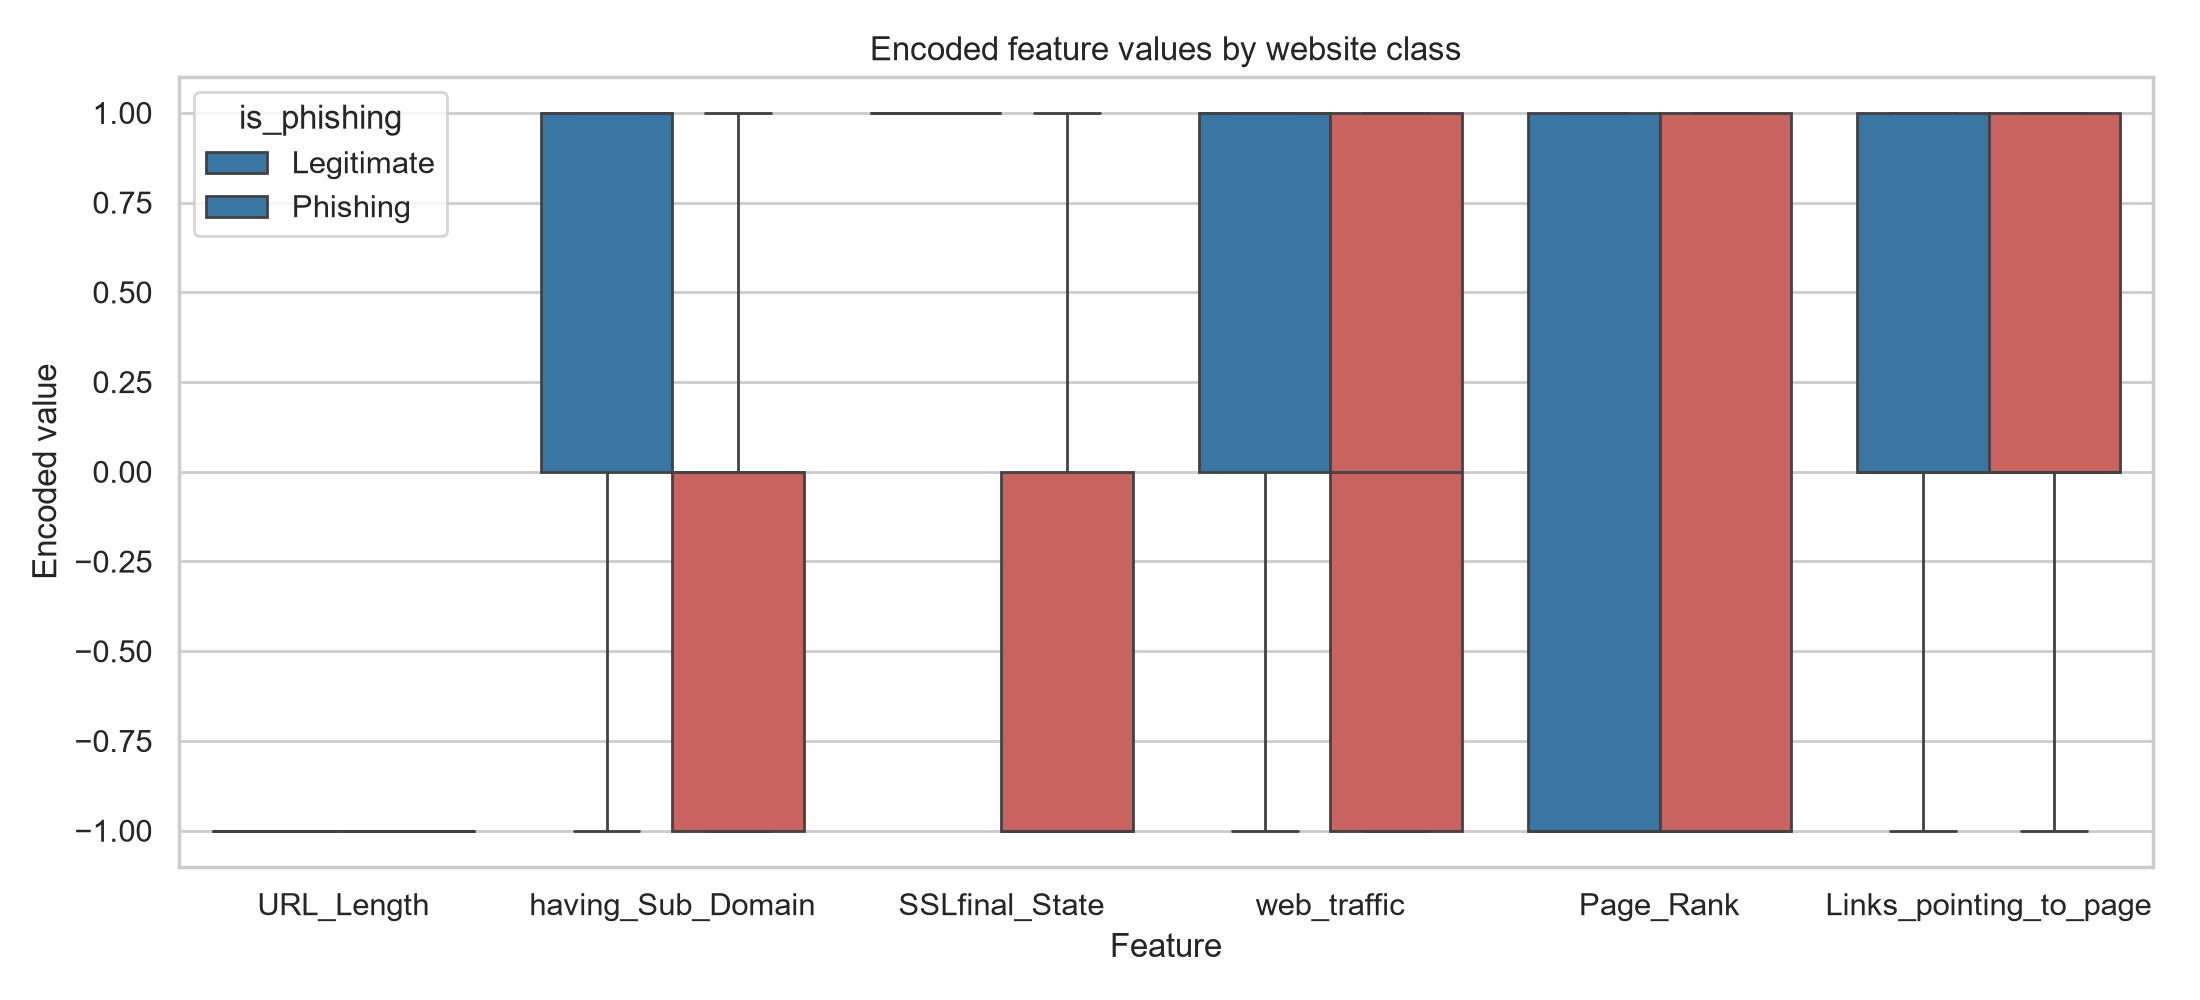

In [6]:
correlations = run_eda(cleaned, missing)
for filename in ['class_distribution.png','missing_values.png','correlation_heatmap.png','feature_distribution.png','feature_boxplots.png']:
    print(filename)
    display(Image(filename='outputs/figures/' + filename))

## 7. Statistical hypothesis testing

Two planned tests use family-wise α=0.05 with Bonferroni adjustment. Welch’s t-test compares encoded `URL_Length` means without assuming equal variances; the chi-square test evaluates independence of `Prefix_Suffix` and class. Effects are Cohen’s d and Cramér’s V. These tests describe association, not causation.

In [7]:
test_results = run_statistical_tests(cleaned)
display(test_results[['test','feature','statistic','p_value','adjusted_p_value_bonferroni','effect_size','effect_size_value','reject_null']])
print(Path('outputs/statistical_results/hypothesis_interpretations.txt').read_text())

,test,feature,statistic,p_value,adjusted_p_value_bonferroni,effect_size,effect_size_value,reject_null
0,Welch independent samples t-test,URL_Length,-4.445963,8.915988e-06,1.783198e-05,Cohen's d,-0.116695,True
1,Pearson chi-square test of independence,Prefix_Suffix,849.645533,8.682168e-187,1.736434e-186,Cramer's V,0.381134,True


Statistical inference (family-wise alpha = 0.05; Bonferroni correction for 2 tests)

Welch t-test compares mean encoded URL_Length values without assuming equal variances; reported 95% CI is for phishing minus legitimate mean.
Chi-square tests independence between the categorical Prefix_Suffix feature and target; Cramer's V measures association.

Welch independent samples t-test â€” URL_Length: statistic=-4.446, p=8.916e-06, Bonferroni p=1.783e-05, effect=Cohen's d -0.1167. Evidence of a class difference in encoded URL_Length; association does not imply causation.

Pearson chi-square test of independence â€” Prefix_Suffix: statistic=849.6, p=8.682e-187, Bonferroni p=1.736e-186, effect=Cramer's V 0.3811. Evidence of association between Prefix_Suffix and phishing class; association does not imply causation.
These tests are descriptive inferential analyses of the available benchmark sample; avoid causal claims.



## 8. Stratified train-test split

In [8]:
X_train, X_test, y_train, y_test, models = train_models(cleaned)
print(f'Train: {len(y_train)} rows; test: {len(y_test)} rows; random_state=42; stratified 80:20.')

Train: 4679 rows; test: 1170 rows; random_state=42; stratified 80:20.


## 9. Majority-class baseline

In [9]:
print('DummyClassifier uses the most frequent training class. Its held-out metrics are included in the same comparison below.')

DummyClassifier uses the most frequent training class. Its held-out metrics are included in the same comparison below.


## 10. Train classifiers

In [10]:
print('Fitted: DummyClassifier, Logistic Regression, Decision Tree, Random Forest.')
print('Logistic Regression uses StandardScaler inside its Pipeline; class weighting is applied to classifiers.')

Fitted: DummyClassifier, Logistic Regression, Decision Tree, Random Forest.
Logistic Regression uses StandardScaler inside its Pipeline; class weighting is applied to classifiers.


## 11. Final held-out evaluation

In [11]:
comparison, best_name = evaluate_models(X_test, y_test, models)
importance = save_importance(models, X_train.columns)
display(comparison)
print('Best by phishing F1, then recall and ROC-AUC:', best_name)

,model,accuracy,precision_phishing,recall_phishing,f1_phishing,roc_auc,test_rows
0,DummyClassifier,0.516239,0.516239,1.000000,0.680947,0.500000,1170
1,Logistic Regression,0.915385,0.924370,0.910596,0.917431,0.977678,1170
2,Decision Tree,0.921368,0.928094,0.918874,0.923461,0.971875,1170
3,Random Forest,0.939316,0.960276,0.920530,0.939983,0.989206,1170


Best by phishing F1, then recall and ROC-AUC: Random Forest


## 12. Classification reports and confusion matrices

DummyClassifier
              precision    recall  f1-score   support

  Legitimate       0.00      0.00      0.00       566
    Phishing       0.52      1.00      0.68       604

    accuracy                           0.52      1170
   macro avg       0.26      0.50      0.34      1170
weighted avg       0.27      0.52      0.35      1170


Logistic Regression
              precision    recall  f1-score   support

  Legitimate       0.91      0.92      0.91       566
    Phishing       0.92      0.91      0.92       604

    accuracy                           0.92      1170
   macro avg       0.92      0.92      0.92      1170
weighted avg       0.92      0.92      0.92      1170


Decision Tree
              precision    recall  f1-score   support

  Legitimate       0.91      0.92      0.92       566
    Phishing       0.93      0.92      0.92       604

    accuracy                           0.92      1170
   macro avg       0.92      0.92      0.92      1170
weighted avg       0.9

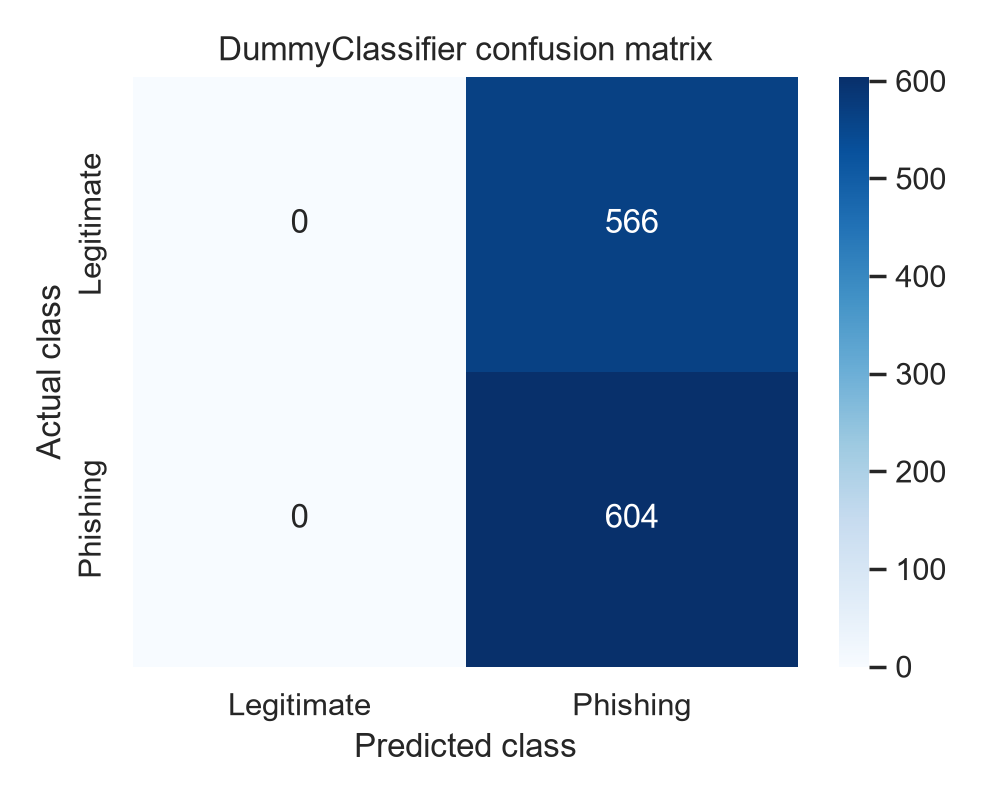

confusion_matrix_logistic_regression.png


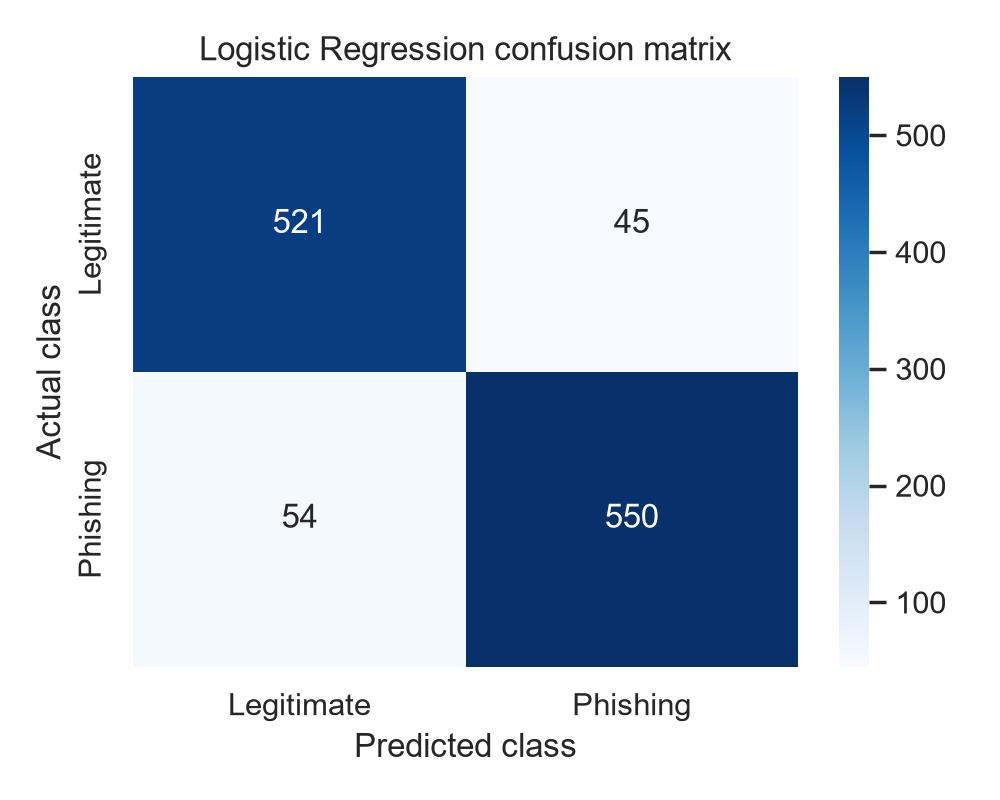

confusion_matrix_decision_tree.png


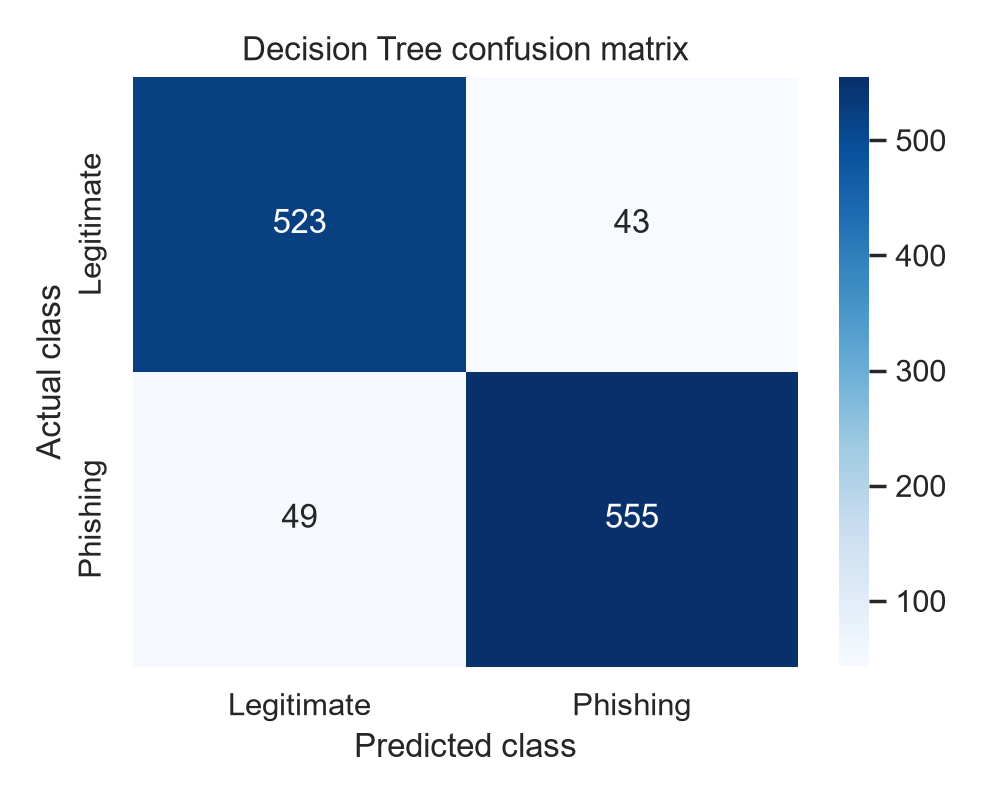

confusion_matrix_random_forest.png


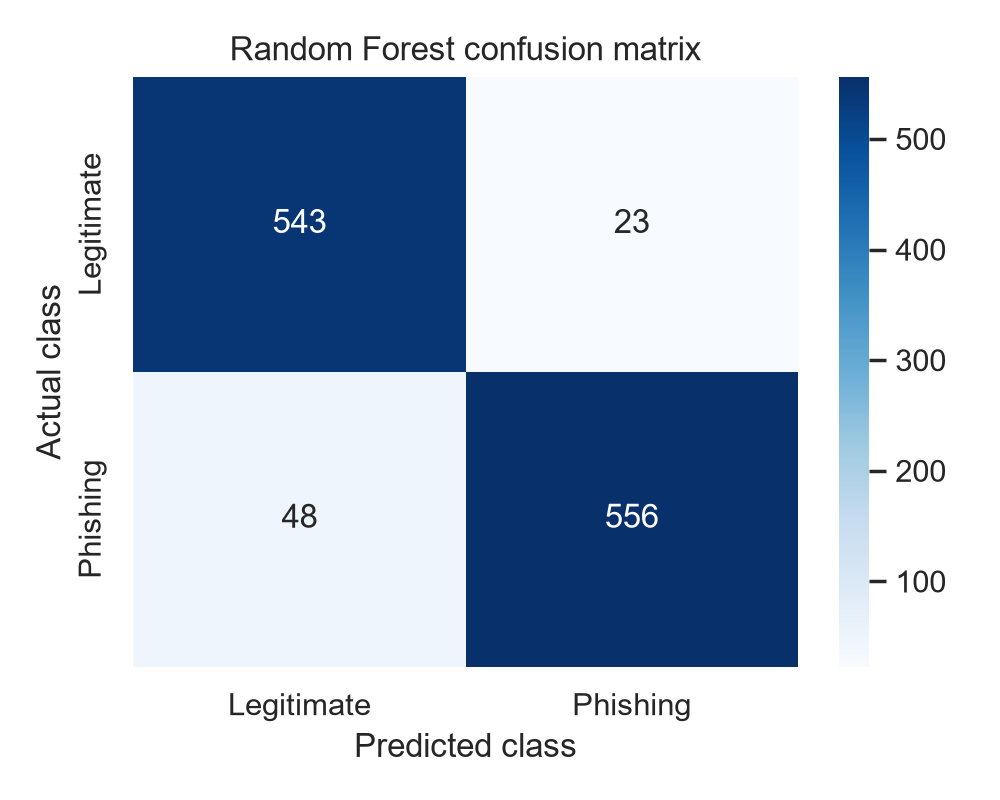

In [12]:
print(Path('outputs/metrics/classification_reports.txt').read_text())
for filename in ['confusion_matrix_dummy.png','confusion_matrix_logistic_regression.png','confusion_matrix_decision_tree.png','confusion_matrix_random_forest.png']:
    print(filename)
    display(Image(filename='outputs/figures/' + filename))

## 13. ROC and precision-recall curves

roc_curve.png


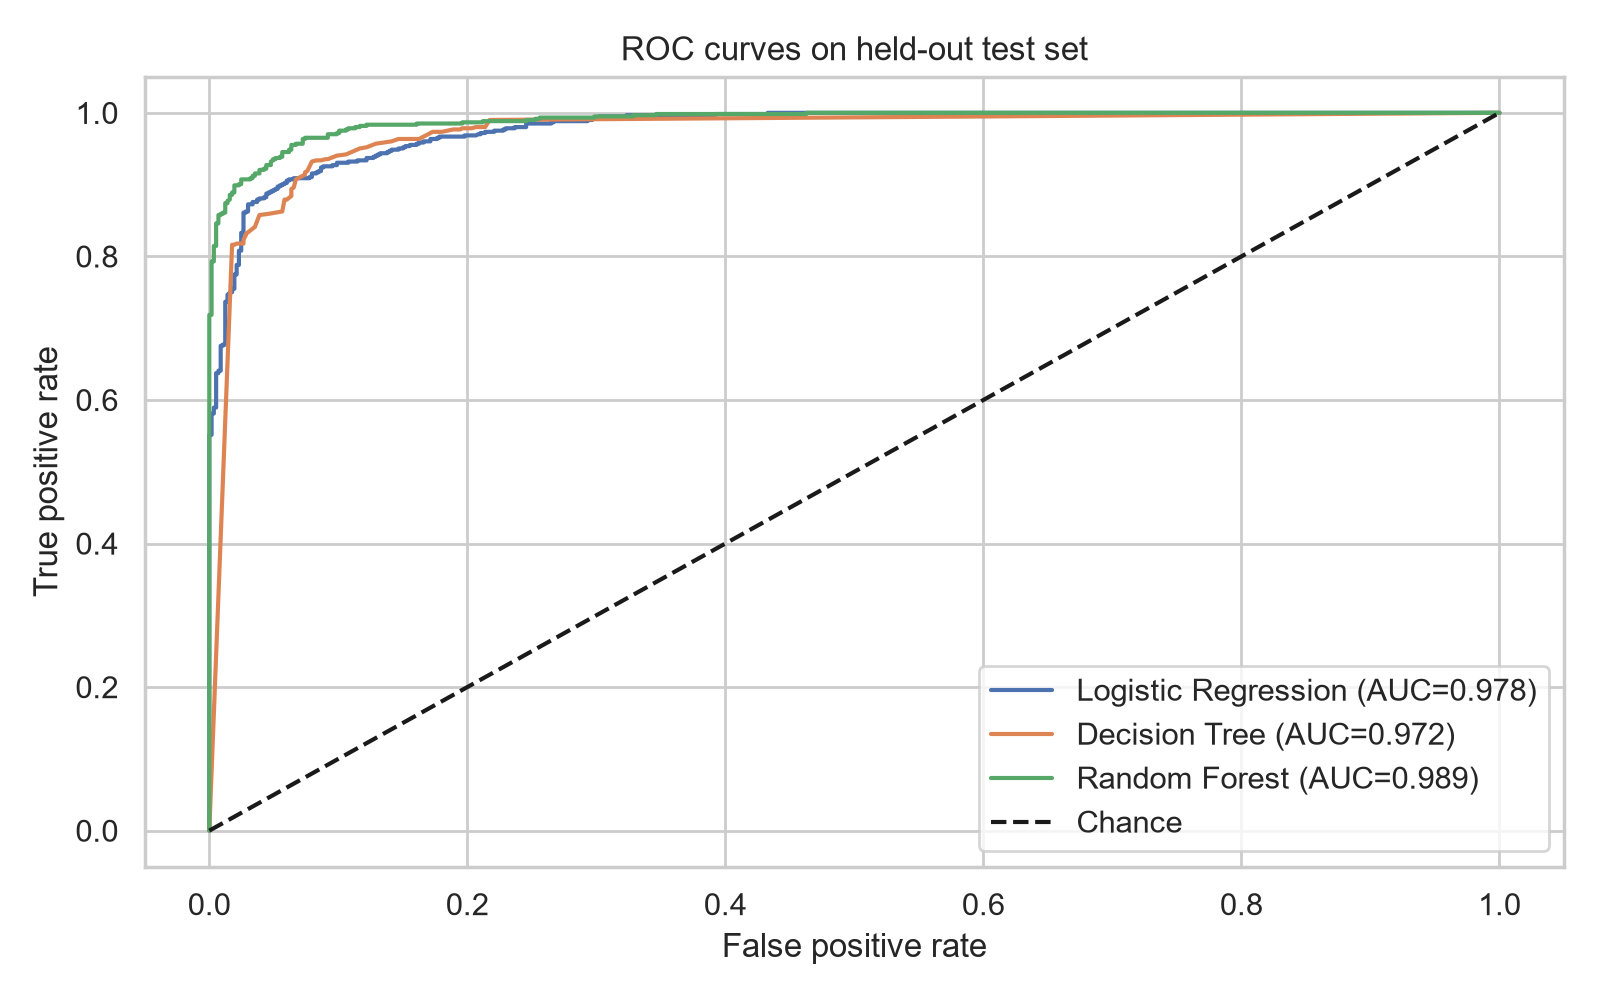

precision_recall_curve.png


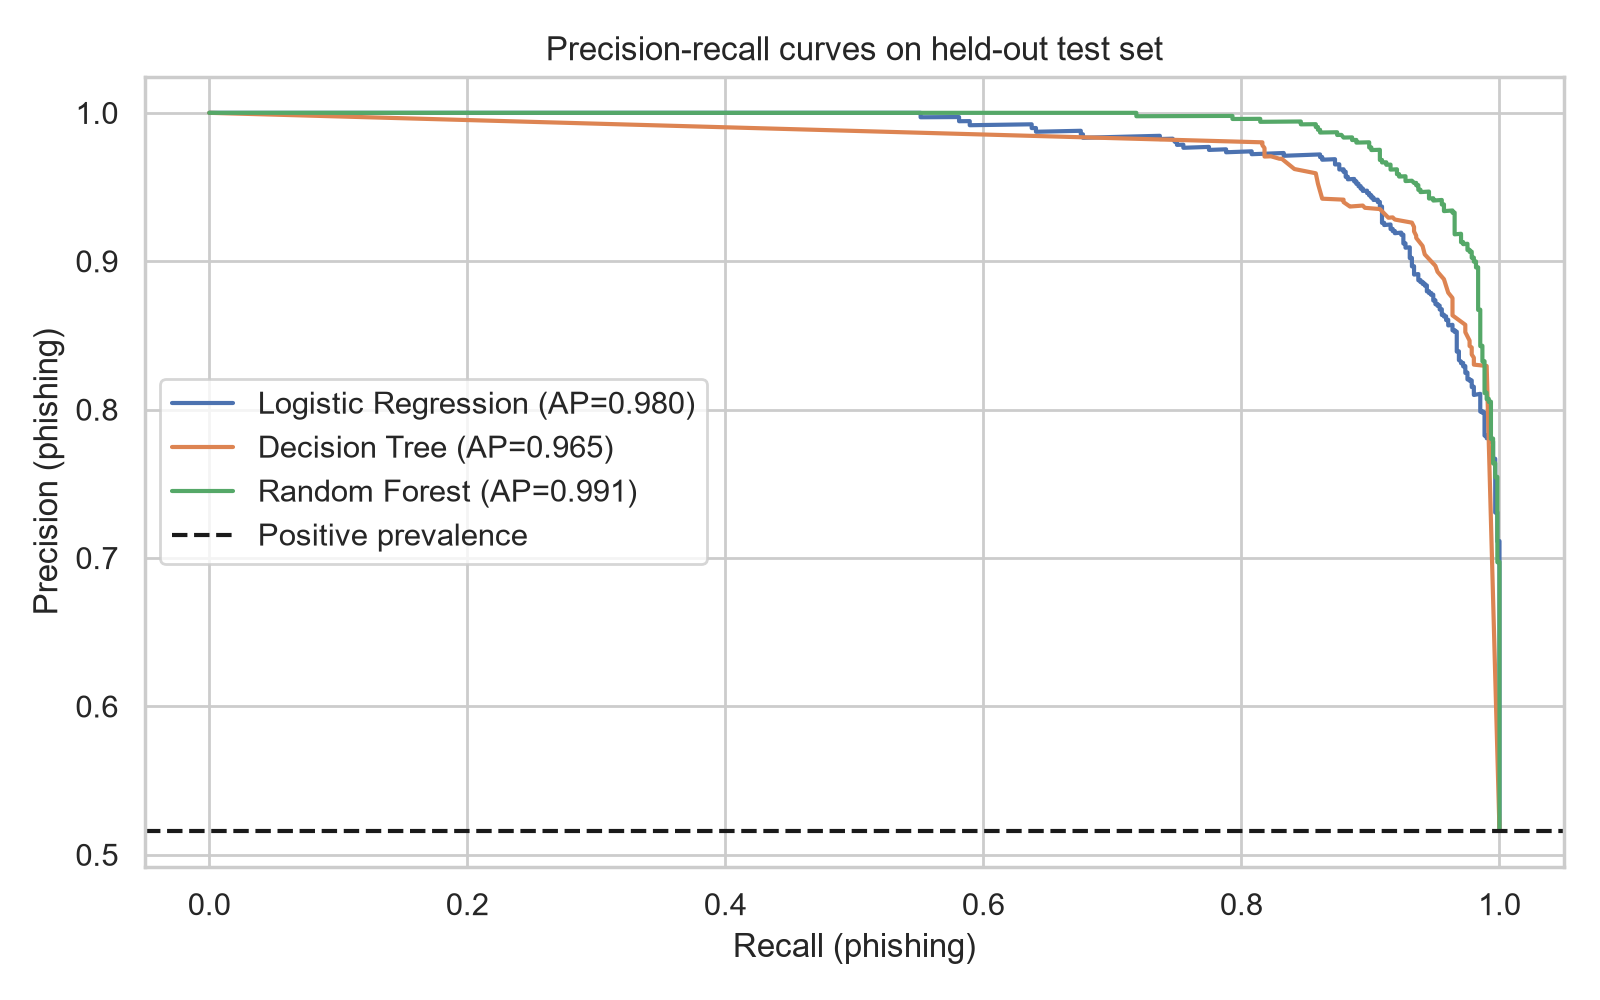

In [13]:
for filename in ['roc_curve.png','precision_recall_curve.png']:
    print(filename)
    display(Image(filename='outputs/figures/' + filename))

## 14. Feature analysis

Random Forest impurity-based feature importance summarizes which features the fitted trees used for predictive splits. It may favor features with particular value distributions and does not show causal effects.

,importance
SSLfinal_State,0.342719
URL_of_Anchor,0.260477
having_Sub_Domain,0.059151
Prefix_Suffix,0.058450
web_traffic,0.053963
Links_in_tags,0.040760
SFH,0.032050
Request_URL,0.016887
Domain_registeration_length,0.014960
Links_pointing_to_page,0.014035


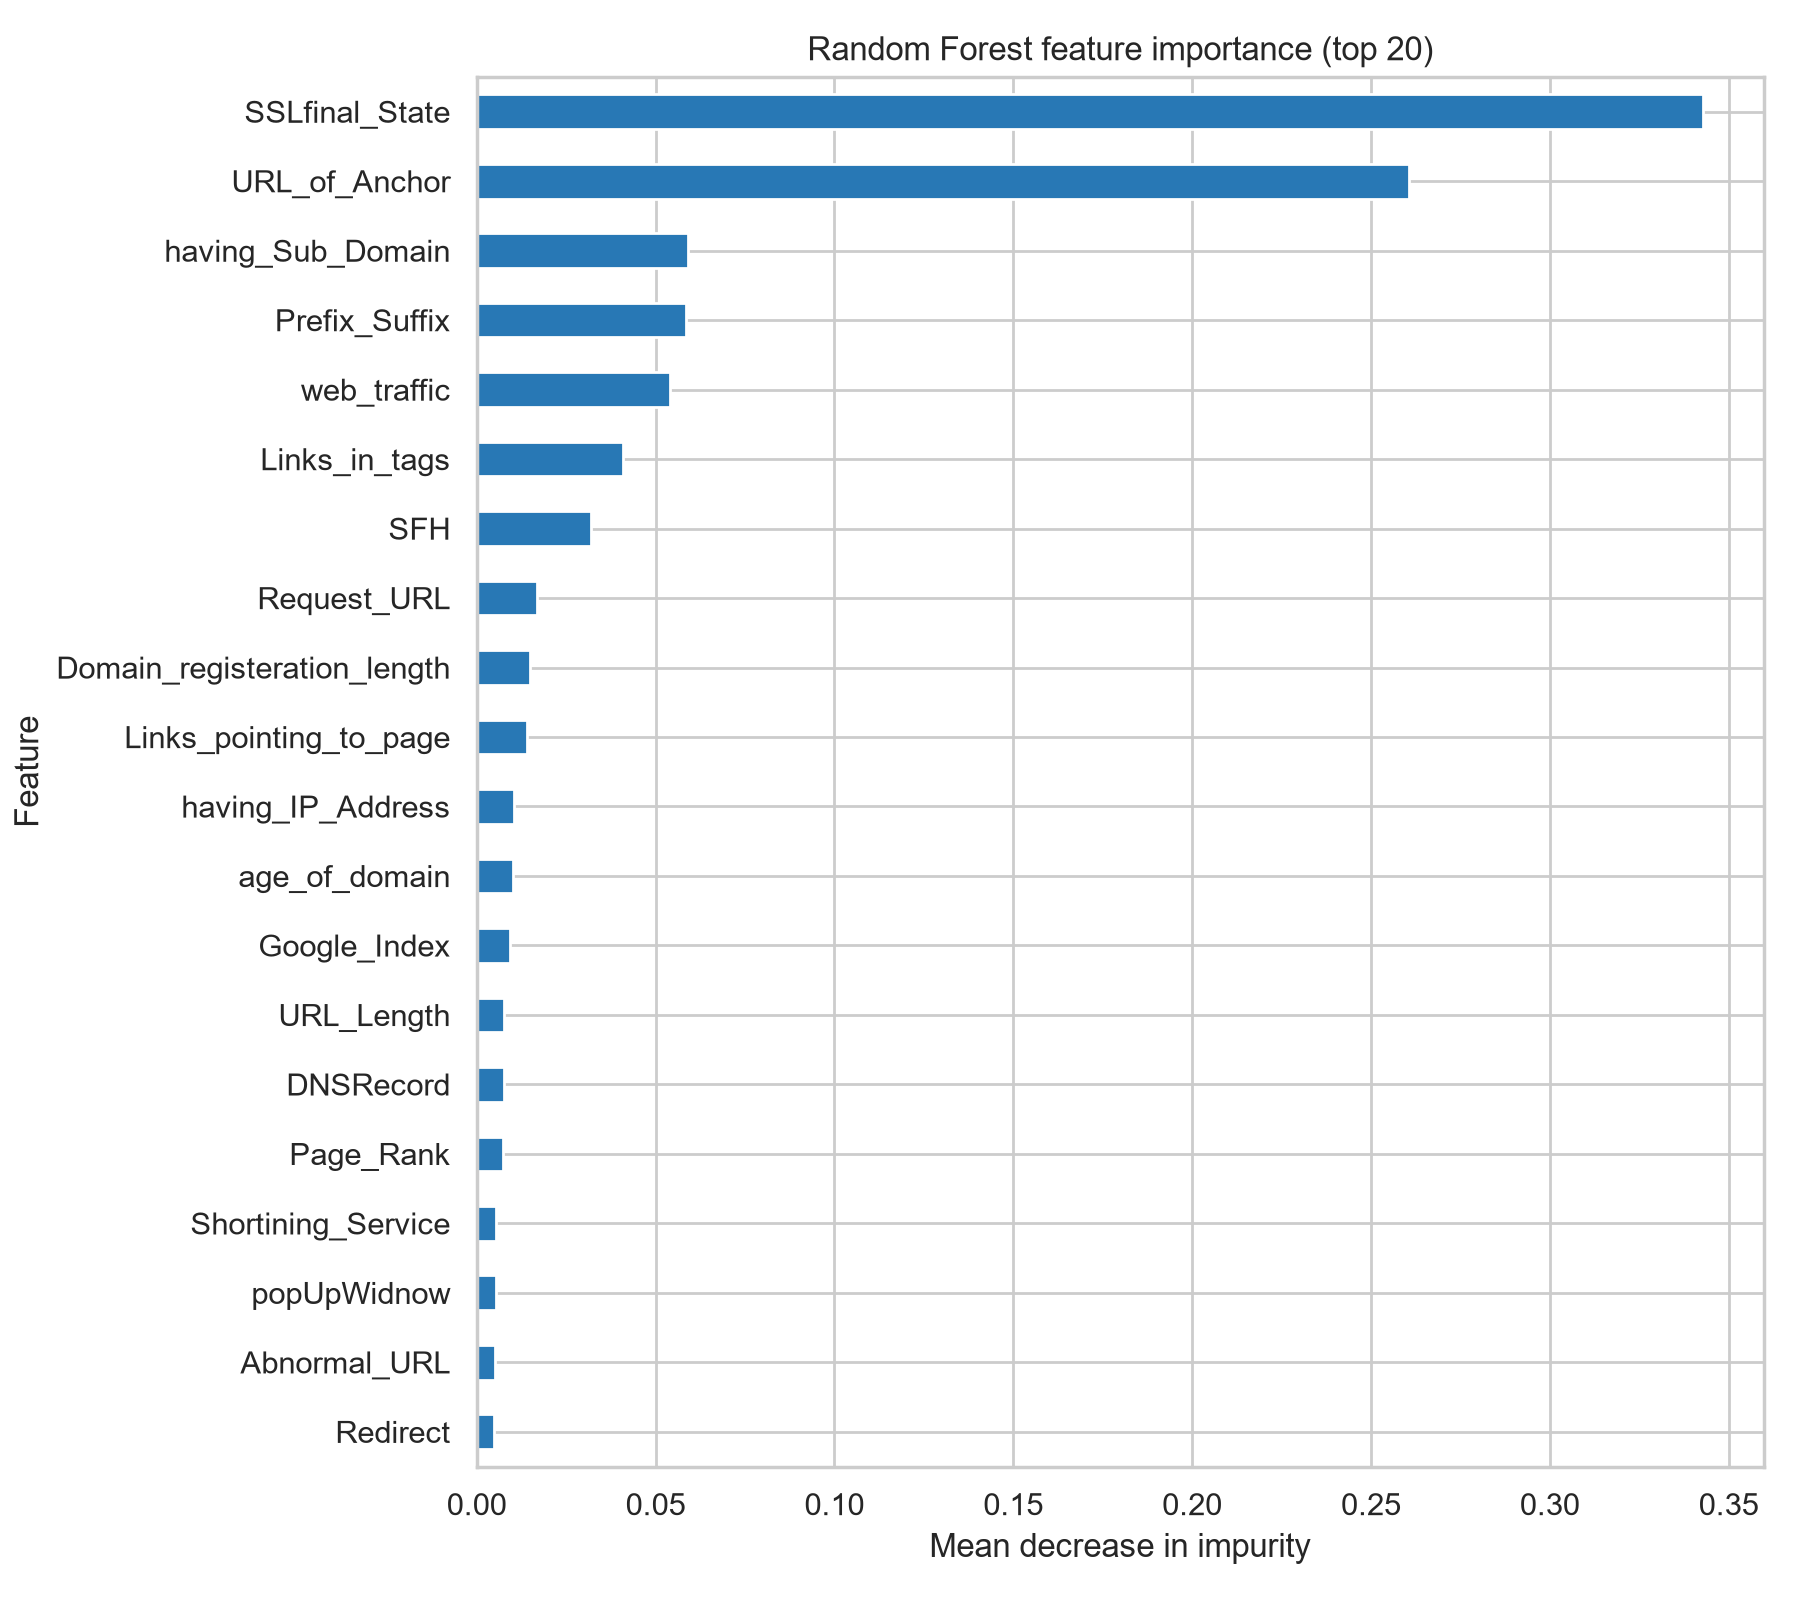

In [14]:
display(importance.head(15).to_frame())
display(Image(filename='outputs/figures/feature_importance.png'))

## 15. Findings and reproducibility

In [15]:
best = comparison.loc[comparison.model == best_name].iloc[0]
print('Best classifier:', best_name)
print('Accuracy:', round(best.accuracy,4), 'Phishing precision:', round(best.precision_phishing,4), 'Phishing recall:', round(best.recall_phishing,4), 'Phishing F1:', round(best.f1_phishing,4), 'ROC-AUC:', round(best.roc_auc,4))
print('Performance is measured on the held-out portion of this UCI benchmark, not newly collected URLs.')

Best classifier: Random Forest
Accuracy: 0.9393 Phishing precision: 0.9603 Phishing recall: 0.9205 Phishing F1: 0.94 ROC-AUC: 0.9892
Performance is measured on the held-out portion of this UCI benchmark, not newly collected URLs.
